In [2]:
import seaborn as sns 
import numpy as np
import pandas as pd

 # Understanding Missing Values in Feature Engineering
when working with real-world data, missing values are a common problem. In feature engineering, handling missing values correctly is crucial because they can affect the performance of machine learning models.

# Types of Missing Values
Missing values can be categorized into three main types: 

# 1. Missing Completely at Random (MCAR)
* the missing values occur randomly and have no relationship with any other variable in the dataset.
* Example: A person forgets to fill in theri age in a survey
* **Effect**: No bias is intorduced, and dropping missing values or imputing them with a simple method like mean/median is usually fine.

# 2. Missing at random (MAR)
* The missing values are related to other observed variables but ot to the missing data itself.
* Example: In a medical dataset, men are more likely to skip answering a question about weight, but within each gender, weight is missing randomly.
* **Effect** : More advanced imputaiton methods like regressioon or using related features to fill in the missing values can be useful.

# 3. Missing Not at Random (MNAR)
* The missing values depend on the unobsered data itiself, meaning the reason for missingness is not random.
* Example : People with igher incomes may choose not to report their salaries in a survey.
* **Effect** : This can introduce bias, and handling MNAR often requires domain knowlede or special techniques like modeling the missingness separately.

# Handling Missing Values in Feature Engineering 
Once we identify the type of missing values, we can decide how to handle them : 

# 1. Removing Missing Values(If missing is Low)

* If a eature has a very few missing values(e.g., <5% of the dataset) simply removing those rows may not impact the model significantly.
* Example :  
      ``df.dropna(inplace=True)``

# 2. Imputation (Filling Missing Values)
* **Mean/Median/Mode Imputation**: Replacing missing values with the mean(for numerical data), median(for skewed numerical data), or mode (for categorical data).  
      ``df['Age'].fillna(df['Age'].mean(), inplace = True) #mean imputation``

 * **Forward or backward fill**: Filling missing values using previous or next available values(good for time series data).  
  
  ``df.fillna(method='ffill' , inplace=True) #forward fill``

 * **Predictive Imputation**: Using models like regressior **KNN** to estimate missing values.  

   ``from sklearn.impute import   KNNImputer imputer = KNNImputer(n_neighbors=3)  df[['Age' , 'Salary']] =imputer.fit_transform(df[['Age' , 'Salary']])``

# 3. Adding Missing Indicators
* Instead of filling missing values, we can create a new column that flags whether a value was missing.  
      `df['Age_missing'] = df['Age'].isnull().astype(int)`

# 4. Using DOmain Knowledge
* In cases of MNAR, sometimes domain expertise can help us decide on the best approach.
* Example : If missing income values indicate high salaries, we might group them as "high income" instead of just imputing with the mean.

# SUMMARY  

| Type of Missing Data | Example | Best Handling Methods |
| :--- | :--- | :--- |
| **MCAR** | Randomly missing age values in a survey | Drop rows or use simple imputation |
| **MAR** | Missing income values depend on education level | Use regression or related features for imputation |
| **MNAR** | High earners not reporting salaries | Use domain knowledge or model missingness |


# Tip
Before deciding how to handle missing values, always **explore your data** to understand the reason behind the missingness. Proper handling can significantly improve  machine learning model's accuracy.

In [3]:
import seaborn as sns

In [4]:
df= sns.load_dataset('titanic')

In [5]:
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [6]:
df.isnull().sum()

survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64

In [7]:
df.shape

(891, 15)

In [8]:
df.dropna().shape

(182, 15)

In [9]:
df.dropna(axis=1) #column deletion

,survived,pclass,sex,sibsp,parch,fare,class,who,adult_male,alive,alone
0,0,3,male,1,0,7.2500,Third,man,True,no,False
1,1,1,female,1,0,71.2833,First,woman,False,yes,False
2,1,3,female,0,0,7.9250,Third,woman,False,yes,True
3,1,1,female,1,0,53.1000,First,woman,False,yes,False
4,0,3,male,0,0,8.0500,Third,man,True,no,True
...,...,...,...,...,...,...,...,...,...,...,...
886,0,2,male,0,0,13.0000,Second,man,True,no,True
887,1,1,female,0,0,30.0000,First,woman,False,yes,True
888,0,3,female,1,2,23.4500,Third,woman,False,no,False
889,1,1,male,0,0,30.0000,First,man,True,yes,True


<Axes: xlabel='age', ylabel='Count'>

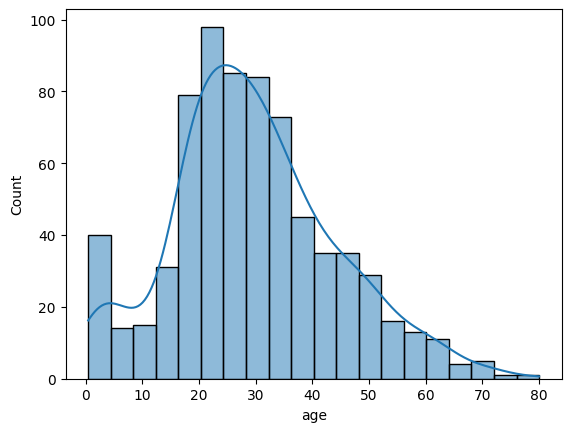

In [16]:
sns.histplot(df['age'],kde=True)

<Axes: xlabel='age', ylabel='Density'>

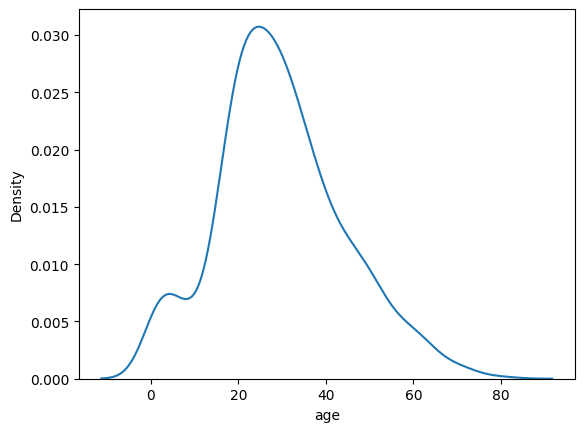

In [17]:
sns.kdeplot(df['age'])

In [22]:
df['age_mean']=df['age'].fillna(df['age'].mean())

In [23]:
df[['age_mean',"age"]]

,age_mean,age
0,22.000000,22.0
1,38.000000,38.0
2,26.000000,26.0
3,35.000000,35.0
4,35.000000,35.0
...,...,...
886,27.000000,27.0
887,19.000000,19.0
888,29.699118,NaN
889,26.000000,26.0


In [24]:
## mean imputation works if data is distributed normally but if we have outliers then solution -> median imputation

df['age_median']=df['age'].fillna(df['age'].median())

In [25]:
df[['age_median','age_mean','age']]

,age_median,age_mean,age
0,22.0,22.000000,22.0
1,38.0,38.000000,38.0
2,26.0,26.000000,26.0
3,35.0,35.000000,35.0
4,35.0,35.000000,35.0
...,...,...,...
886,27.0,27.000000,27.0
887,19.0,19.000000,19.0
888,28.0,29.699118,NaN
889,26.0,26.000000,26.0


In [26]:

# mode imputation -> categorical values
df[df['embarked'].isnull()]

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone,age_mn,age_mean,age_median
61,1,1,female,38.0,0,0,80.0,NaN,First,woman,False,B,NaN,yes,True,38.0,38.0,38.0
829,1,1,female,62.0,0,0,80.0,NaN,First,woman,False,B,NaN,yes,True,62.0,62.0,62.0


In [27]:
df['embarked'].unique()

array(['S', 'C', 'Q', nan], dtype=object)

In [28]:
mode_value=df[df['embarked'].notna()]['embarked'].mode()[0]

In [29]:
mode_value

'S'

In [30]:
df['embarked_mode']=df['embarked'].fillna(mode_value)


In [34]:
df[['embarked_mode','embarked']]

,embarked_mode,embarked
0,S,S
1,C,C
2,S,S
3,S,S
4,S,S
...,...,...
886,S,S
887,S,S
888,S,S
889,C,C


In [41]:
df[df['embarked'].isnull()]

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone,age_mn,age_mean,age_median,embarked_mode
61,1,1,female,38.0,0,0,80.0,NaN,First,woman,False,B,NaN,yes,True,38.0,38.0,38.0,S
829,1,1,female,62.0,0,0,80.0,NaN,First,woman,False,B,NaN,yes,True,62.0,62.0,62.0,S


In [42]:
df['embarked_mode'].isnull().sum()

np.int64(0)

<Axes: ylabel='age'>

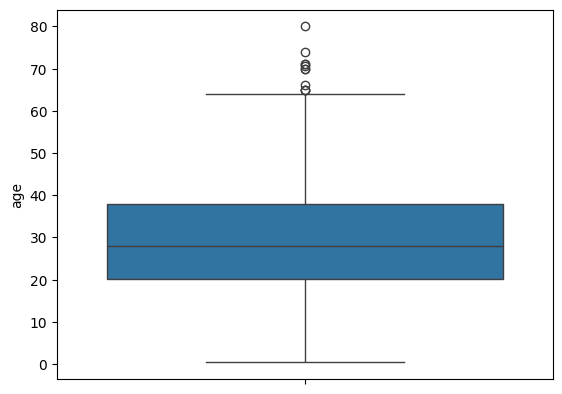

In [39]:
sns.boxplot(data=df['age'])